# Minimal GP Test: Real Field Data

Two fixed tasks: missing route-segment estimation and forward prediction. Accurate clock synchronization is accepted as an experimental assumption. All parameters and preprocessing use training observations only. Full methods and dependencies are in the [README](README.md).

The route holdout uses both past and later observations; the forward test uses only earlier observations. There are no online updates, policy comparisons or navigation runs.

In [1]:
from pathlib import Path
import csv, json, hashlib, html
from IPython.display import display, HTML, Image
root=Path.cwd()
run=root/'result'/json.loads((root/'result'/'latest.json').read_text())['run']
def read_csv(p):
    with p.open(newline='',encoding='utf-8') as f: return list(csv.DictReader(f))
def table(headers,rows):
    def line(values,tag): return '<tr>'+''.join(f'<{tag}>{html.escape(str(v))}</{tag}>' for v in values)+'</tr>'
    display(HTML('<table>'+line(headers,'th')+''.join(line(r,'td') for r in rows)+'</table>'))
metrics=read_csv(run/'metrics.csv')
table(['Task','Model','RMSE °C','MAE °C','95% coverage','Interval width °C','Marginal NLPD'],
      [[r['task'],r['model']]+[f'{float(r[k]):.4f}' if r[k] else 'n/a' for k in
        ['rmse_c','mae_c','coverage_95','mean_interval_width_c','marginal_nlpd']] for r in metrics])
print('Run:',run.name)
print('Coverage is for noisy observations. Baselines have no assigned uncertainty intervals.')

Task,Model,RMSE °C,MAE °C,95% coverage,Interval width °C,Marginal NLPD
blocked_reconstruction,train_mean,0.1598,0.1313,n/a,n/a,n/a
blocked_reconstruction,temporal_gp,0.1619,0.1336,0.9694,0.7225,-0.3863
blocked_reconstruction,spatiotemporal_gp,0.1321,0.1007,1.0000,0.8733,-0.4130
forward_prediction,train_mean,0.1963,0.1633,n/a,n/a,n/a
forward_prediction,last_observation,0.1395,0.1141,n/a,n/a,n/a
forward_prediction,temporal_gp,0.1894,0.1558,0.9422,0.7171,-0.2571
forward_prediction,spatiotemporal_gp,0.2206,0.1883,1.0000,0.9593,-0.1007


Run: run_20261105T025050681058Z
Coverage is for noisy observations. Baselines have no assigned uncertainty intervals.


## Splits and held-out predictions

Partitions were fixed before fitting. Position and time are correlated along this moving route, so the forward task is not a pure fixed-location temporal forecast. Shaded bands include learned observation noise.

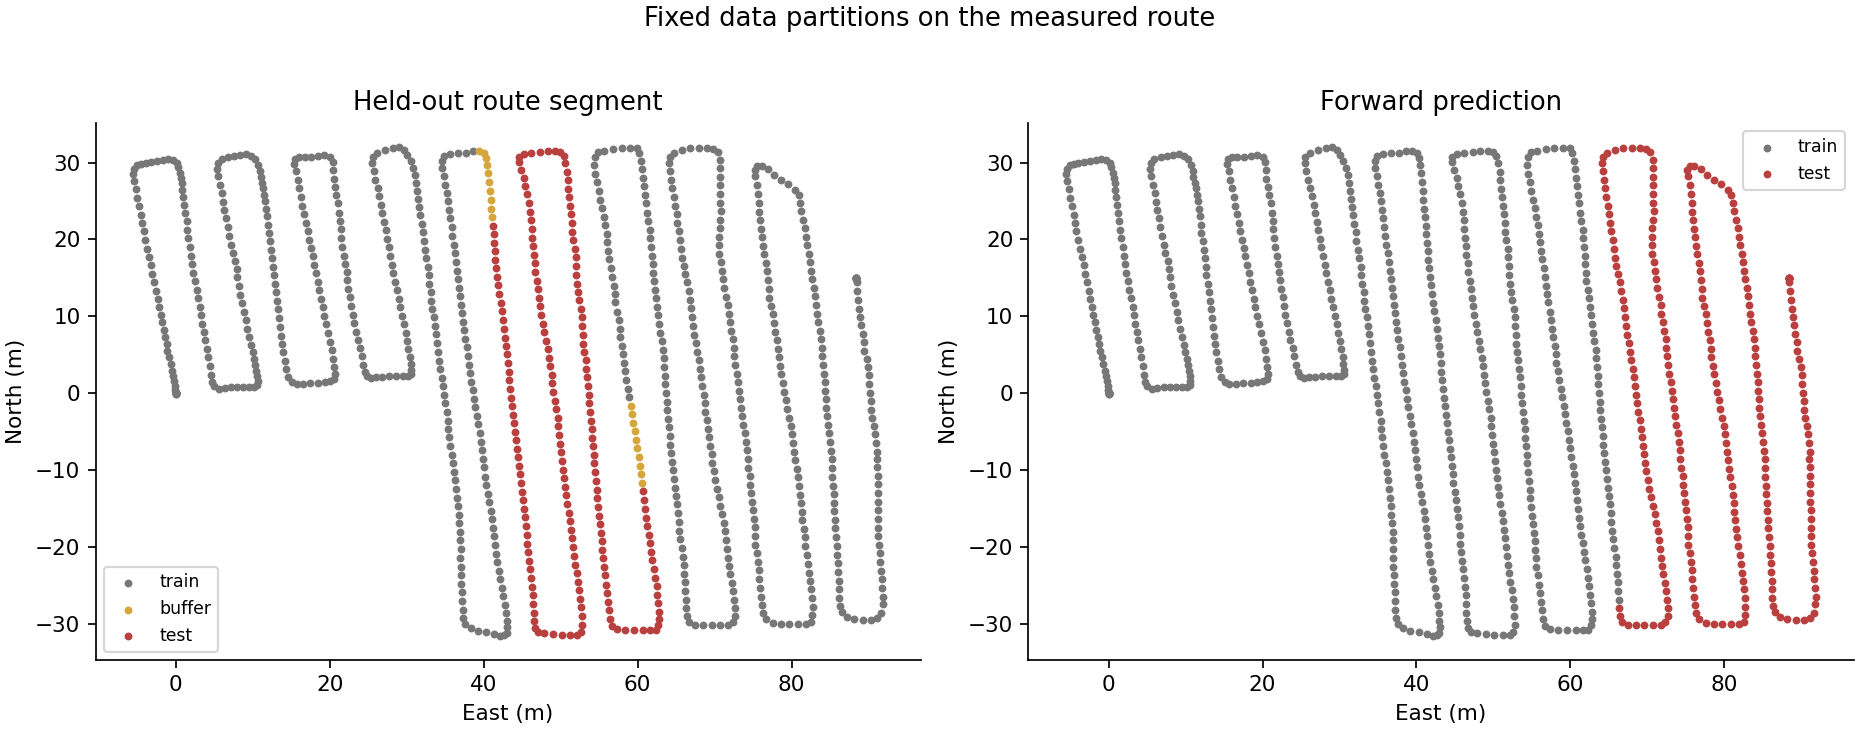

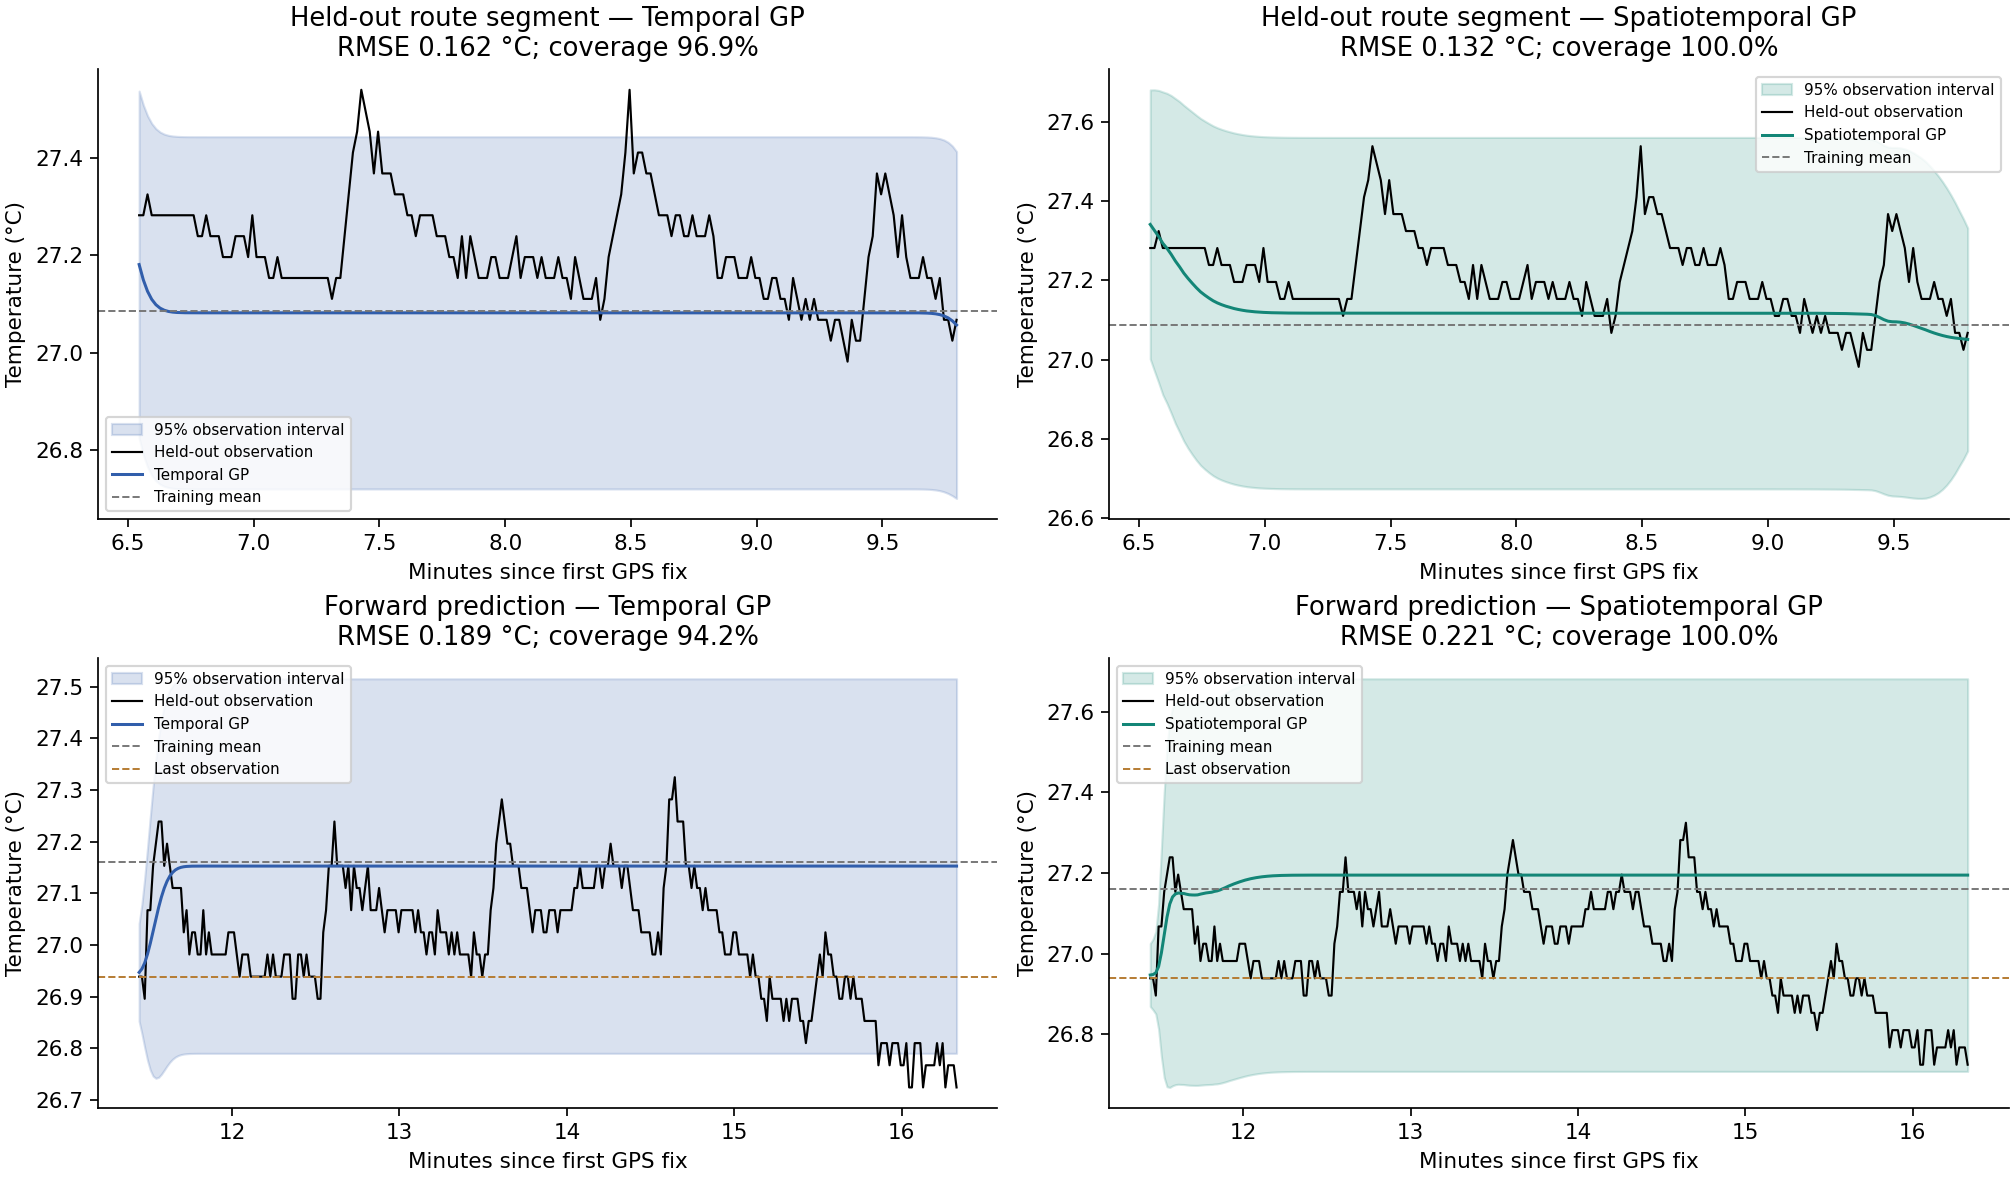

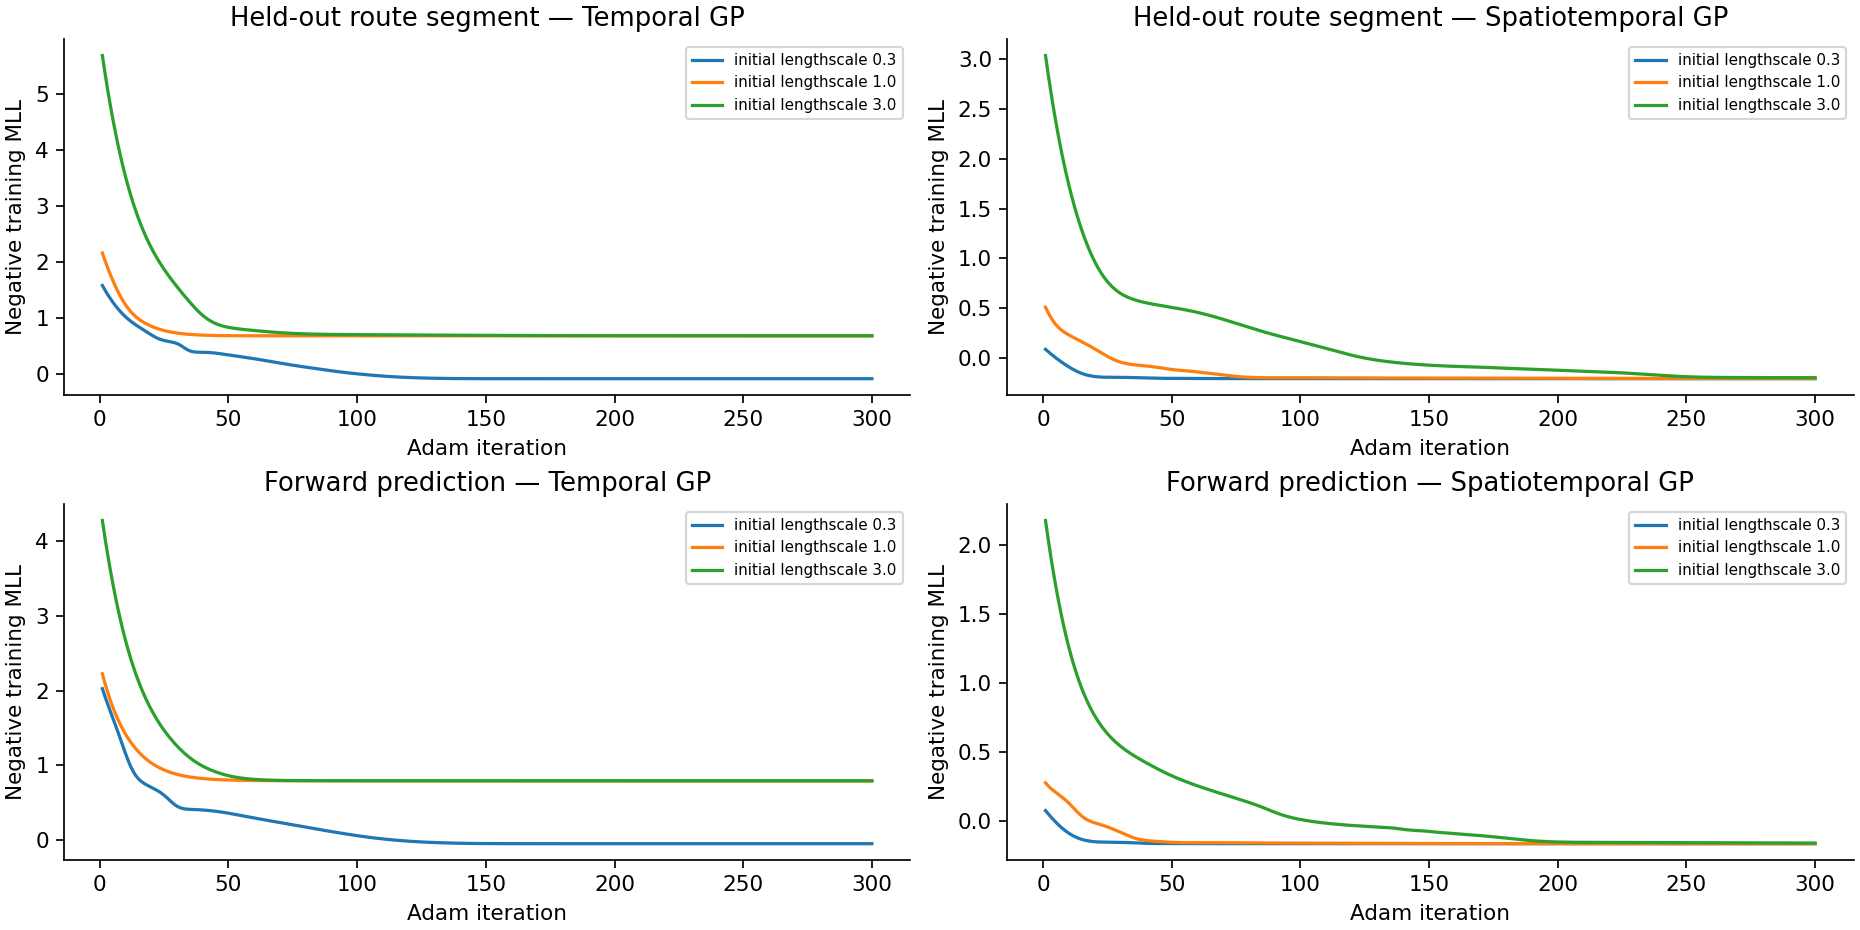

In [2]:
for name in ['splits.png','predictions.png','training.png']:
    display(Image(filename=str(root/'result'/'figures'/name),embed=True))

## Parameters and checks

These fitted parameters describe this run under the chosen model. Different initializations may give different training optima; selection uses training marginal likelihood only. They are not validated universal field parameters. The three starts are not independent data replicates.

In [3]:
hp=json.loads((run/'hyperparameters.json').read_text())
rows=[]
for task,models in hp.items():
    for model,h in models.items():
        length=h.get('lengthscales_m_m_s',[h.get('lengthscale_seconds')])
        rows.append([task,model,', '.join(f'{v:.3f}' for v in length),f"{h['noise_variance_c2']**.5:.4f}",h['selected_initial_lengthscale_scaled']])
table(['Task','Model','Lengthscales (x m, y m, t s; or t s)','Noise SD °C','Selected initial scale'],rows)
m=json.loads((run/'manifest.json').read_text())
for name,expected in m['outputs'].items():
    assert hashlib.sha256((run/name).read_bytes()).hexdigest()==expected,name
v=json.loads((run/'verification.json').read_text()); assert v['passed']
rv=json.loads((root/'result'/'report_verification.json').read_text()); assert rv['passed']
print(len(v['checks']),'worker checks passed;',rv['verified_metric_rows'],'metric rows independently verified.')
print('Source clock assumption accepted; no independent synchronization certification is claimed.')

Task,Model,"Lengthscales (x m, y m, t s; or t s)",Noise SD °C,Selected initial scale
blocked_reconstruction,temporal_gp,5.182,0.0297,0.3
blocked_reconstruction,spatiotemporal_gp,"3.336, 25.886, 15.915",0.0294,0.3
forward_prediction,temporal_gp,5.143,0.0306,0.3
forward_prediction,spatiotemporal_gp,"3.607, 20.436, 17.278",0.0303,0.3


43 worker checks passed; 7 metric rows independently verified.
Source clock assumption accepted; no independent synchronization certification is claimed.


## Findings

- **Held-out route segment:** Spatiotemporal GP has the lowest RMSE (0.1321 °C). Spatiotemporal GP RMSE is 0.1321 °C versus 0.1619 °C for temporal GP and 0.1598 °C for the training mean.
- **Forward prediction:** Last observation has the lowest RMSE (0.1395 °C). Spatiotemporal GP RMSE is 0.2206 °C versus 0.1894 °C for temporal GP and 0.1963 °C for the training mean.

The plotted GP means largely return to their learned constant levels away from training support and miss the local peaks. The selected forward spatiotemporal GP has a temporal lengthscale of 17.3 s, while the maximum prediction horizon is 294 s and the median nearest-training spatial distance is 14.8 m. This is consistent with weak correlation to the training data over much of the forecast. Spatiotemporal GP interval coverage is 100% in these two splits, with mean widths 0.873 °C and 0.959 °C; broad intervals do not establish precise predictions or calibrated 95% coverage. The data-to-GP pipeline is working, but this experiment does not support a forecasting advantage over persistence.

Performance and predictive coverage must be judged separately from numerical correctness. The comparison covers one mobile run and two fixed partitions. It does not validate dense field reconstruction, multi-day prediction, unique spatial/temporal parameter identification or policy superiority. Future observations were used for scoring only in the forward test.

These results provide a diagnostic starting point for subsequent GP/ROS work. They do not establish a deployment-ready kernel.